In [16]:
import numpy as np
import matplotlib.pyplot as plt
import math

rng = np.random.default_rng(24601)

In [17]:
# add the `golden` function here

from math import sqrt

def golden(phi, x0, x1, kmax=200, tol=1.e-8):
    varphi = 0.5*(1 + sqrt(5))
    
    for k in range(1,kmax):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)
        
        if phi(x3) < phi(x2):
            x0 = x2
        else:
            x1 = x3
    
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)
    
        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    
    return xnew


def bisection(bound1, bound2, func):
    for i in range(20):
        if func(bound1)*func(0.5*(bound1+bound2)) < 0:
            bound1 = bound1
            bound2 = 0.5*(bound1+bound2)
        
        else:
            if func(0.5*(bound1+bound2))*func(bound2) < 0:
                bound1 = 0.5*(bound1+bound2)
                bound2 = bound2
    
            else:
                break
    return 0.5*(bound1 + bound2)
    

def func_phi(xs):
    return xs**4 - 9*xs**3 + 25*xs**2 - 24*xs + 4


def neg_func_phi(xs):
    return -(xs**4 - 9*xs**3 + 25*xs**2 - 24*xs + 4)


def func_phi_prime(xs):
    return 4*xs**3 - 27*xs**2 + 50*xs - 24
    
# add docstrings and comments explaining what the function does

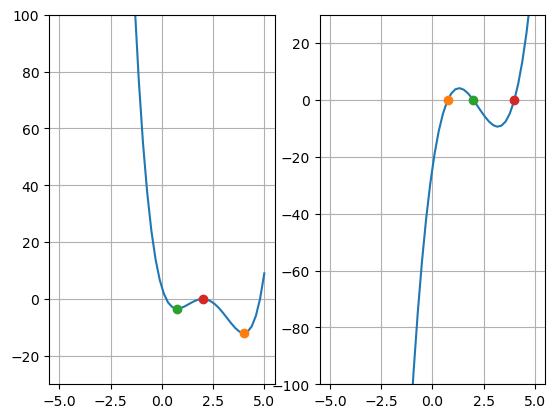

In [18]:
# define Eq. (1)

# use golden search to locate minimum

xs = np.linspace(-5,5)
zeroes = np.zeros(np.size(xs))


fig, (ax1, ax2) = plt.subplots(1, 2)

ax1.plot(xs, func_phi(xs))
ax1.plot(golden(func_phi, 0, 5), func_phi(golden(func_phi, 0, 5)),
        marker="o")
ax1.plot(golden(func_phi, -2, 2), func_phi(golden(func_phi, -2, 2)),
        marker="o")
ax1.plot(golden(neg_func_phi, 0, 4), func_phi(golden(neg_func_phi, 0, 4)),
        marker="o")
ax1.set_ylim(-30,100)


ax2.plot(xs, func_phi_prime(xs))
ax2.plot(bisection(0, 1, func_phi_prime), func_phi_prime(bisection(0, 1, func_phi_prime)),
        marker="o")
ax2.plot(bisection(1, 3, func_phi_prime), func_phi_prime(bisection(1, 3, func_phi_prime)),
        marker="o")
ax2.plot(bisection(3, 5, func_phi_prime), func_phi_prime(bisection(3, 5, func_phi_prime)),
        marker="o")

ax2.set_ylim(-100, 30)
ax1.grid()
ax2.grid()


plt.savefig("golden.png")
plt.show()
# report figure 1


In [19]:
# add the `termcrit` function here
def termcrit(xolds,xnews):
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)


# add the `gradient` function here
def gradient(phi,xs,h=1.e-6):
    n = xs.size
    phi0 = phi(xs)
    Xph = (xs*np.ones((n,n))).T + np.identity(n)*h
    grad = (phi(Xph) - phi0)/h
    return grad

    
# add the `descent` function here
def descent(phi, gradient, xolds, gamma=0.15, kmax=200, tol=1.e-8):
    for k in range(1, kmax):
        grad = gradient(phi, xolds)
        xnews = xolds - gamma * grad
        err = termcrit(xolds, xnews)

        if err < tol:
            print(f"Converged at iteration {k}")
            return xnews
            
        xolds = np.copy(xnews)
        
    print(f"Reached max iterations ({kmax}).")
    return xnews
    

# add docstrings and comments explaining what the functions do

In [20]:
# COMPLETE THIS FUNCTION
def spherical_to_cartesian(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)
    
    returns Nx3 array of particle positions in cartesian coords
    """
    N = len(sphe_params) // 2
    thetas = sphe_params[:N]
    phis = sphe_params[N:]
    
    x = np.sin(thetas)*np.cos(phis)
    y = np.sin(thetas)*np.sin(phis)
    z = np.cos(thetas)
    
    return np.column_stack((x, y, z))


def compute_dist(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)

    returns distance matrix where ij is the distance between ith and jth particle
    """
    pos = spherical_to_cartesian(sphe_params, R0)
    diff = pos[:, np.newaxis, :] - pos[np.newaxis, :, :]
    dist_matrix = np.linalg.norm(diff, axis=-1)
    return dist_matrix

def electrostatic_potential(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)

    returns total electrostatic potential
    """
    # Guard: handle 2D matrix input passed from gradient()
    # if sphe_params.ndim == 2:
    #     return np.array([electrostatic_potential(sphe_params[:, j], R0) for j in range(sphe_params.shape[1])])

    d_matrix = compute_dist(sphe_params, R0)
    
    # calculate N dynamically from the input array length
    N_local = len(sphe_params) // 2
    i_upper, j_upper = np.triu_indices(N_local, k=1)
    distances = d_matrix[i_upper, j_upper]
        
    return np.sum(1.0 / distances)

In [21]:
# COMPLETE THIS CODE BLOCK

rng = np.random.default_rng(24601)
pi = np.pi

def rand(xa, xb, num):
    rand_cont = np.array([])
    for i in range(num):
        rs = rng.uniform(xa, xb)
        rand_cont = np.append(rand_cont, rs)
    return rand_cont

N =  60
init_theta =  rand(0, pi, N)
init_phi = rand(0, 2*pi, N)


xolds = np.hstack((init_theta, init_phi)) # this is the 1d array where the first half is the thetas and 2nd half is the phis

xnews = descent(electrostatic_potential, gradient, xolds)


#for i in range(100):
 #   xs = descent(electrostatic_potential, gradient, xs, gamma=0.01)
  #  print(electrostatic_potential(xs))

#  0.01, 500

xs = descent(electrostatic_potential, gradient, xolds, gamma=0.01, kmax=500)

print(electrostatic_potential(xs))
print(electrostatic_potential(xnews))

# use descent function and `xolds` to calculate the positions that minimizes the cost function
# you may need to test different gamma values (test diff values with your classmates to see which values are closest to theo)



Reached max iterations (200).
Reached max iterations (500).
3281.6735145153625
2200.102640142856


In [22]:
# from N=2 up to 20 (or more), generate the optmized positions and calculate the corresponding minimized potential energies
# for each N, always initialize a random array of positions of N particles

# theoretical list of potential energies from N=2 to N=60
u_thom = [
    0.500000000, 1.732050808, 3.674234614, 6.474691495, 9.985281374,
    14.452977414, 19.675287861, 25.759986531, 32.716949460, 40.596450510,
    49.165253058, 58.853230612, 69.306363297, 80.670244114, 92.911655302,
    106.050404829, 120.084467447, 135.089467557, 150.881568334, 167.641622399,
    185.287536149, 203.930190663, 223.347074052, 243.812760299, 265.133326317,
    287.302615033, 310.491542358, 334.634439920, 359.603945904, 385.530838063,
    412.261274651, 440.204057448, 468.904853281, 498.569872491, 529.122408375,
    560.618887731, 593.038503566, 626.389009017, 660.675278835, 695.916744342,
    732.078107544, 769.190846459, 807.174263085, 846.188401061, 886.167113639,
    927.059270680, 968.713455344, 1011.557182654, 1055.182314726, 1099.819290319,
    1145.418964319, 1191.922290416, 1239.361474729, 1287.772720783, 1337.094945276,
    1387.383229253, 1438.618250640, 1490.773335279, 1543.830400976
] 

# REPORT FIGURE: generate a plot of U vs N 
# compare theoretical and those calculated from gradient descent
# add axes labels and legends

Reached max iterations (500).


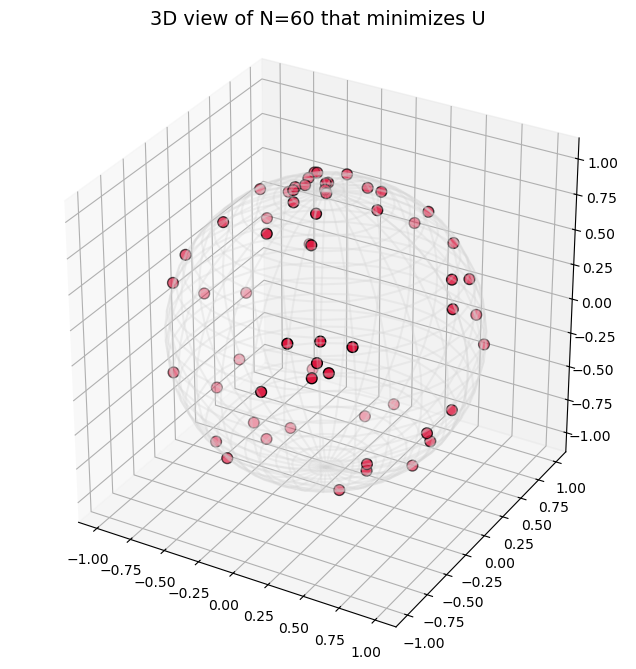

In [24]:
# OPTIONAL
# for 3d plotting of N=60 (it might take a minute to process)

N = 60
init_theta = rand(0, pi, N) 
init_phi = rand(0, 2*pi, N) 
xolds = np.hstack((init_theta, init_phi))
xnews = descent(electrostatic_potential, gradient, xs, gamma=0.01, kmax=500)

# calculate the spherical coordinates of N particles that minimizes
pos = spherical_to_cartesian(xnews)
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Draw wireframe sphere
u = np.linspace(0, 2 * np.pi, 30)
v = np.linspace(0, np.pi, 30)
x_sp = np.outer(np.cos(u), np.sin(v))
y_sp = np.outer(np.sin(u), np.sin(v))
z_sp = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_wireframe(x_sp, y_sp, z_sp, color='lightgrey', alpha=0.3)

# Plot charge positions
ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], color='crimson', s=60, edgecolors='k', depthshade=True)

ax.set_box_aspect([1, 1, 1])
ax.set_title('3D view of N=60 that minimizes U', fontsize=14)
plt.savefig("config.png")
plt.show()
